In [2]:
# Import all required library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

In [3]:
# load data CC_Customer_Dataset

df = pd.read_csv('CC_Customer_Dataset.csv')

# Inspect Records
df.head()

,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB


In [5]:
# Feature Selection
X = df.iloc[:, [2, 3]] # slice the features

In [6]:
print(X.head())

   Avg_Credit_Limit  Total_Credit_Cards
0            100000                   2
1             50000                   3
2             50000                   7
3             30000                   5
4            100000                   6


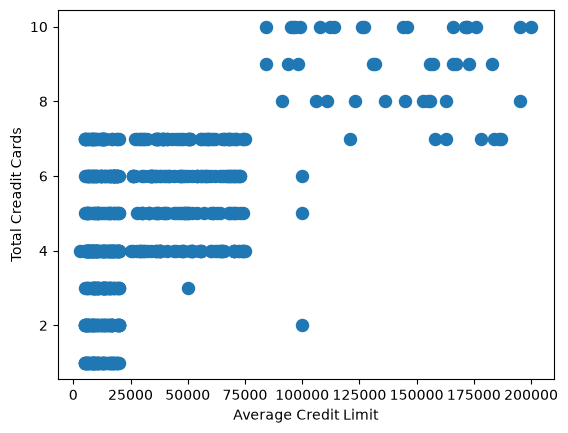

In [7]:
# Make a scatterplot for 2 variables using SepalLengthCm and SepalWidthCm
plt.xlabel('Average Credit Limit')
plt.ylabel('Total Creadit Cards')
plt.scatter(X.iloc[:,0], X.iloc[:,1], s=75)

# Question 1
Can the distribution of the data be considered linear?

# Answer 1
No, the data distribution doesn't appear to be linear . Because a linear relation data should be have correlation between variable x with y, where if variable x increases, y variable should be up too following by how upscale/improvment/downscale the x variable. Help on visualization from scatter plot above, the connection between 2 variable not given linear pattern but the distribution seems like more scatter. 

In [8]:
# Standardization
from sklearn.preprocessing import StandardScaler

# Creating Standardization object
scaler = StandardScaler()

# Standaridazation 2 variable
X_scaled = scaler.fit_transform(X)

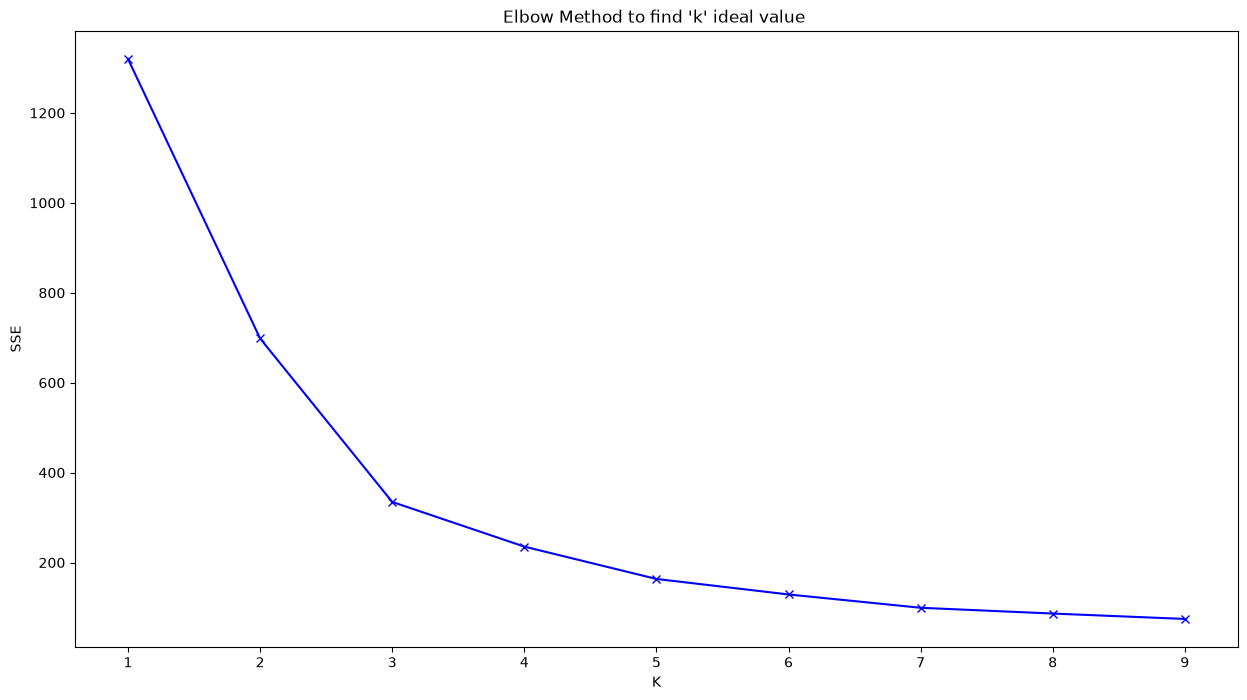

In [9]:
sse = []

K = range(1, 10)

for k in K:
    kmeanModel = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeanModel.fit(X_scaled)
    sse.append(kmeanModel.inertia_)

plt.figure(figsize=(15,8))
plt.title("Elbow Method to find 'k' ideal value ")
plt.plot(K, sse, "bx-")
plt.xlabel("K")
plt.ylabel("SSE")
plt.show()

After using <i>elbow method</i> and get the line char above, i can assume that value 3 is the optimal number for k. 

In [10]:
# Build a K-Means Model
from sklearn.cluster import KMeans

cl_kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

y_kmeans = cl_kmeans.fit_predict(X_scaled)

In [11]:
# Print SSE value
print(f'SSE Value: {cl_kmeans.inertia_}')

SSE Value: 334.72447276058585


# Question 2

Construct a clustering model using the K-Means algorithm. Determine the optimal number k using elbow method. Supplement your analysis with line chart and provide an analytical rationale for why you selected that value.

# Answer 2

The Elbow Method was applied to determine the optimal number of clusters (K) by calculating the Sum of Squared Errors (SSE) for different values of K, ranging from 1 to 9.Based on the resulting line chart, the SSE decreases significantly as the number of clusters increases from K = 1 to K = 3. However, after K = 3, the reduction in SSE becomes progressively smaller, indicating that adding more clusters provides diminishing improvements. Therefore, K = 3 is considered a reasonable candidate for the optimal number of clusters based on the elbow point observed in the chart.

# Question 3
Depict the clustering results from the K-Means model using a scatter plot.

# Answer 3 in the bellow

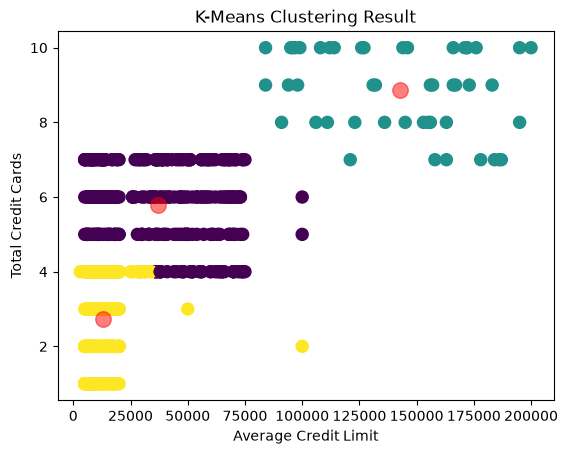

In [12]:
# Plot the clustering result
plt.xlabel('Average Credit Limit')
plt.ylabel('Total Credit Cards')
plt.title('K-Means Clustering Result')
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s = 75, c = y_kmeans)

# plotting the centroid from model K-Means
centers = cl_kmeans.cluster_centers_

# Return centroid scale into original scale
centers_ori = scaler.inverse_transform(centers)
plt.scatter(centers_ori[:, 0], centers_ori[:, 1],  c='red', s = 125, alpha=0.5)

In [13]:
# Identify the optimal number of clusters using silhouette score

from sklearn.metrics import silhouette_score

print(silhouette_score(X_scaled, y_kmeans))

0.49005001704500417


The value indicates that data are not clustered sufficiently well

In [14]:
print(df.columns)
df.head()

Index(['Sl_No', 'Customer Key', 'Avg_Credit_Limit', 'Total_Credit_Cards',
       'Total_visits_bank', 'Total_visits_online', 'Total_calls_made'],
      dtype='str')


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


In [15]:
# Feature Selection to collect usable variables

X_dbscan = df[
    [
        'Avg_Credit_Limit',
        'Total_Credit_Cards',
        'Total_visits_bank',
        'Total_visits_online',
        'Total_calls_made'
    ]
]

print(X_dbscan.head())

   Avg_Credit_Limit  Total_Credit_Cards  Total_visits_bank  \
0            100000                   2                  1   
1             50000                   3                  0   
2             50000                   7                  1   
3             30000                   5                  1   
4            100000                   6                  0   

   Total_visits_online  Total_calls_made  
0                    1                 0  
1                   10                 9  
2                    3                 4  
3                    1                 4  
4                   12                 3  


In [16]:
# Standardization the scale because of gap value between variables
from sklearn.preprocessing import StandardScaler

scaler_dbscan = StandardScaler()

X_dbscan_scaled = scaler_dbscan.fit_transform(X_dbscan)

Determine epsilon value

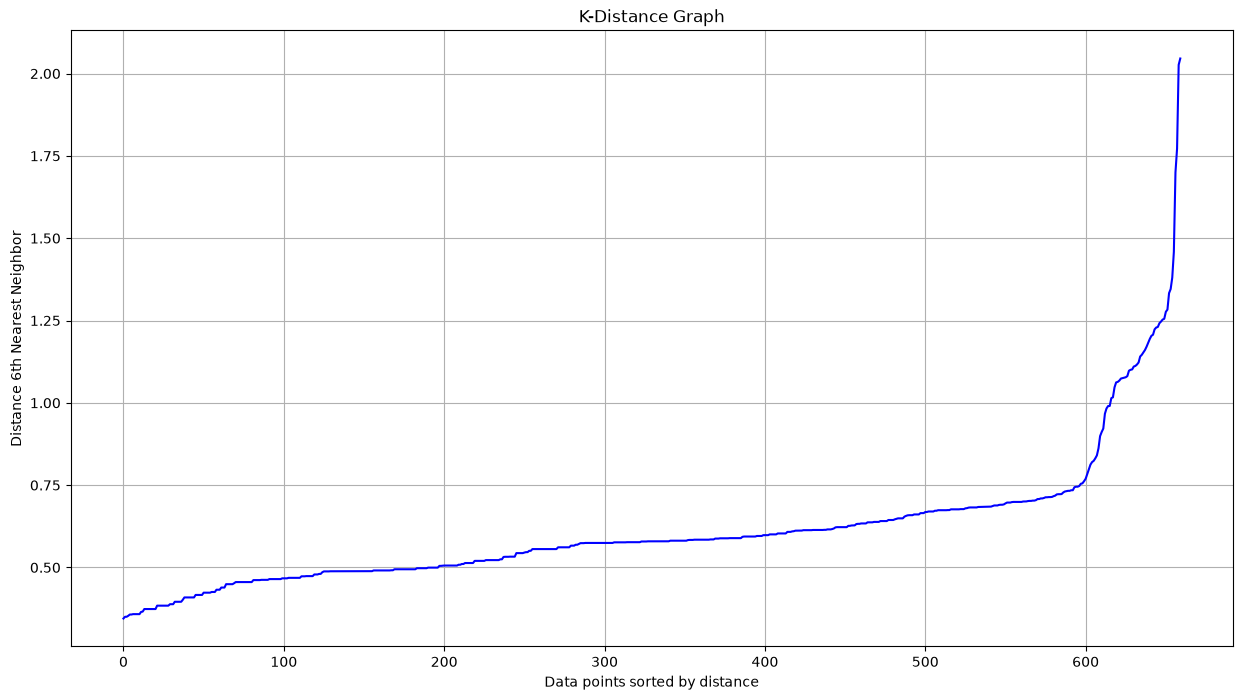

In [17]:
# require library for create K-Distance Graph
from sklearn.neighbors import NearestNeighbors

# Deterime neighbors number
min_samples = 6

# Create NearestNeighbors model
neighbors = NearestNeighbors(n_neighbors=min_samples)

# Train model using standardized data
neighbors.fit(X_dbscan_scaled)

# Calculate the distance and index of nearest neighbours
distances, indices = neighbors.kneighbors(X_dbscan_scaled)

k_distances = np.sort(distances[:, min_samples-1])

# Made K-Distance Graph
plt.figure(figsize=(15,8))
plt.plot(k_distances, 'b-')
plt.title('K-Distance Graph')
plt.xlabel('Data points sorted by distance')
plt.ylabel('Distance 6th Nearest Neighbor')
plt.grid(True)
plt.show()

Base on this K-Distance Graph, we get epsilon value around 0.75

# Question 4
Construct a clustering model using DBSCAN with all usable variables

# Answer 4 is bellow

In [18]:
# import library for DBSCAN
from sklearn.cluster import DBSCAN

# create DBSCAN model with min_samples = 6
dbscan = DBSCAN(eps=0.75, min_samples=min_samples)

# Doing the clustering using DBSCAN model
cluster_db = dbscan.fit_predict(X_dbscan_scaled)

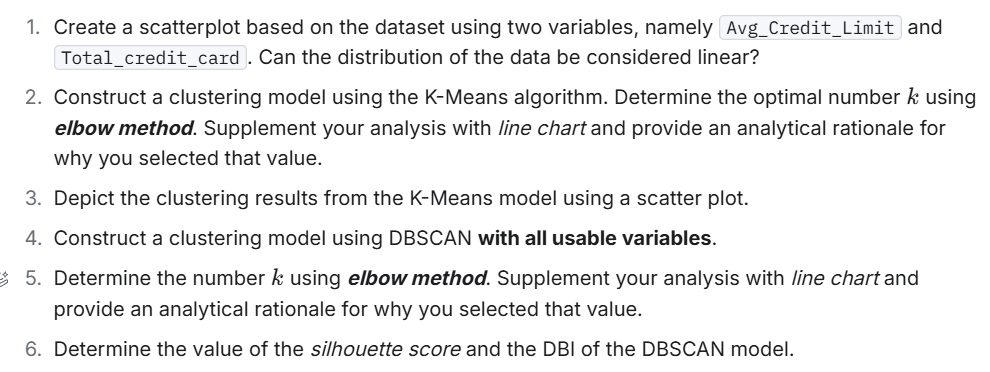

In [19]:
# Mengidentifikasi label cluster
unique_labels = set(cluster_db)

# Menghitung jumlah cluster (tanpa noise)
n_clusters = len(unique_labels) - (1 if -1 in unique_labels else 0)

# Menghitung jumlah noise
n_noise = list(cluster_db).count(-1)

# Menampilkan hasil clustering
print(f"Jumlah Cluster: {n_clusters}")
print(f"Jumlah Noise: {n_noise}")
print(f"Total Data: {len(cluster_db)}")

Jumlah Cluster: 2
Jumlah Noise: 49
Total Data: 660


# Question 5
Determine the number k using <i>elbow method</i>. Supplement your analysis with line chart and provide an analytical rationale for why you selected that value

# Answer 5
For the answer number 5, the number of cluster DBSCAN is 2. Not because determine from Elbow Method, but founded automatically after the model execute with parametric eps=0.75 and min_samples=6. After that, running the code above to determine the number of cluster.

In [20]:
from sklearn.metrics import silhouette_score
	
print(silhouette_score(X_dbscan_scaled, cluster_db))

0.4696524286028266


In [22]:
from sklearn.metrics import davies_bouldin_score
	
db = davies_bouldin_score(X_dbscan_scaled, cluster_db)
	
print(f"Davies-Bouldin Index: {db}")

Davies-Bouldin Index: 2.3444966320238527


The value of the silhouette score = 0.4696524286028266 and the DBI of the DBSCAN model = 2.3444966320238527